In [1]:
%pip uninstall opencv-python opencv-contrib-python opencv-python-headless --quiet -y
%pip install -e ../streetview osmnx geopandas matplotlib tqdm opencv-contrib-python-headless numpy zxing-cpp pyzbar --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [20]:
import sys

if sys.platform.startswith("linux"):
    out = !dpkg -l | grep libzbar-dev
    if not out:
        raise RuntimeError("libzbar-dev is not installed.")

In [2]:
import osmnx as ox

name = "Jersey City, New Jersey, United States"
boundary = ox.geocode_to_gdf(name)

boundary["display_name"]

0    Jersey City, Hudson County, New Jersey, United...
Name: display_name, dtype: str

<Axes: >

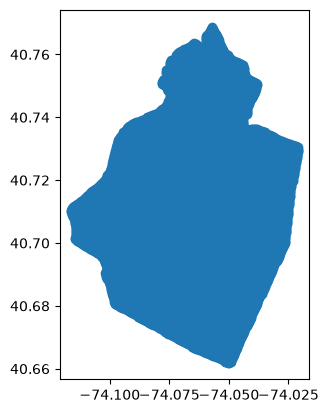

In [3]:
# Sample points every 50 meters within the boundary
import geopandas as gpd
from shapely.geometry import Point

distance = 50  # meters
boundary = boundary.to_crs(epsg=3857)  # Project to meters
minx, miny, maxx, maxy = boundary.total_bounds
points: list[Point] = []
x = minx
while x <= maxx:
    y = miny
    while y <= maxy:
        point = Point(x, y)
        if boundary.contains(point).any():
            points.append(point)
        y += distance
    x += distance
points_gdf = gpd.GeoDataFrame(geometry=points, crs=boundary.crs)
points_gdf = points_gdf.to_crs(epsg=4326)  # Convert back to lat/lon
points_gdf.plot()

In [4]:
import sqlite3
from contextlib import contextmanager

@contextmanager
def get_conn():
    conn = sqlite3.connect('google_maps.db')
    c = conn.cursor()
    c.execute("PRAGMA foreign_keys = ON;")
    try:
        yield conn, c
    finally:
        conn.commit()
        conn.close()

# Connect to SQLite database (or create it if it doesn't exist)
with get_conn() as (conn, c):

    # Create table of searches
    # Maps (lat, lon) to a list of (id, lat, lon, heading, pitch, roll, date)
    c.execute("PRAGMA foreign_keys = ON;")
    c.execute("PRAGMA journal_mode=WAL")
    c.execute("PRAGMA synchronous=NORMAL")

    c.execute('''
        CREATE TABLE IF NOT EXISTS search_locations (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            lat REAL NOT NULL,
            lon REAL NOT NULL,
            UNIQUE(lat, lon)
        )
    ''')

    c.execute('''
        CREATE TABLE IF NOT EXISTS panoramas (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            lat REAL NOT NULL,
            lon REAL NOT NULL,
            pano_id TEXT NOT NULL,
            location_id INTEGER NOT NULL,
            heading REAL,
            pitch REAL,
            roll REAL,
            capture_date TEXT,
            searched_for_qrs BOOLEAN DEFAULT 0,
            FOREIGN KEY (location_id) REFERENCES search_locations(id) ON DELETE CASCADE,
            UNIQUE(pano_id)
        )
    ''')
    
    c.execute('''
        CREATE TABLE IF NOT EXISTS qrs (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            pano_id INTEGER NOT NULL,
            qr_data TEXT NOT NULL,
            FOREIGN KEY (pano_id) REFERENCES panoramas(id) ON DELETE CASCADE
        )
    ''')

In [5]:
with get_conn() as (conn, c):
    c.execute("DROP TABLE qrs")

In [6]:
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
from streetview import search_panoramas

MAX_WORKERS = 16     # network-bound; raise until you see rate limiting/errors
COMMIT_EVERY = 50    # batch commits instead of one fsync per point

panoramas_found_by_point = {}

def fetch(key, lat, lon, retries=3):
    # Runs in a worker thread: ONLY network, never touches the DB.
    for attempt in range(retries):
        try:
            return key, lat, lon, search_panoramas(lat, lon), None
        except Exception as e:
            if attempt == retries - 1:
                return key, lat, lon, None, e   # signal failure; don't record it
            time.sleep(2 ** attempt)            # simple backoff

with get_conn() as (conn, c):
    c.execute("""
        SELECT sl.id, sl.lat, sl.lon, COUNT(p.id) AS pano_count
        FROM search_locations sl
        LEFT JOIN panoramas p ON p.location_id = sl.id
        GROUP BY sl.id
    """)
    existing = {(lat, lon): (lid, cnt) for lid, lat, lon, cnt in c.fetchall()}

    total = 0
    new_points = []
    for point in points_gdf.itertuples():
        lat, lon = point.geometry.y, point.geometry.x
        key = (lat, lon)
        if key in existing:
            cnt = existing[key][1]
            panoramas_found_by_point[key] = cnt
            total += cnt
        else:
            new_points.append((key, lat, lon))

    pbar = tqdm(total=len(new_points))
    done = 0
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = [ex.submit(fetch, k, la, lo) for k, la, lo in new_points]
        for fut in as_completed(futures):
            key, lat, lon, panoramas, err = fut.result()
            if err is not None:
                pbar.update(1) 
                continue

            c.execute("INSERT INTO search_locations (lat, lon) VALUES (?, ?)", (lat, lon))
            location_id = c.lastrowid
            for pano in panoramas:
                c.execute("""
                    INSERT OR IGNORE INTO panoramas
                        (pano_id, location_id, lat, lon, heading, pitch, roll, capture_date)
                    VALUES (?, ?, ?, ?, ?, ?, ?, ?)
                """, (pano.pano_id, location_id, lat, lon,
                      pano.heading, pano.pitch, pano.roll, pano.date))

            panoramas_found_by_point[key] = len(panoramas)
            total += len(panoramas)
            done += 1
            if done % COMMIT_EVERY == 0:
                conn.commit()
            pbar.update(1)
            pbar.set_postfix({'count': len(panoramas), 'total': total})

    conn.commit()
    pbar.close()

100%|██████████| 4/4 [00:03<00:00,  1.03it/s]


<Axes: >

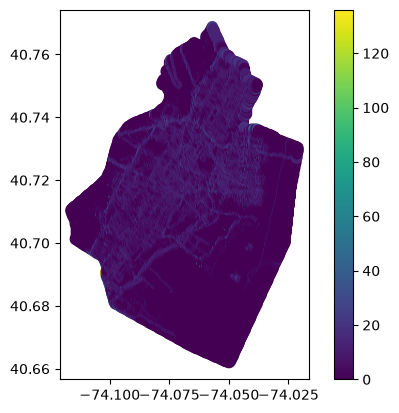

In [7]:
# Plot panoramas found by point
df = gpd.GeoDataFrame(
    [{'geometry': gpd.points_from_xy([lon], [lat])[0], 'count': count} for (lat, lon), count in panoramas_found_by_point.items()],
    crs="EPSG:4326"
)
df.plot(column='count', cmap='viridis', legend=True, markersize=50)

In [9]:
# Test tonnelle proxy
PROXY_IP = "http://129.153.7.152:1080"
import requests

response = requests.get("http://ifconfig.me", proxies={"http": PROXY_IP, "https": PROXY_IP})
print("First: ", response.text)
response = requests.get("http://ifconfig.me", proxies={"http": PROXY_IP, "https": PROXY_IP})
print("Second: ", response.text)

First:  2001:470:88d3:ab8:5212:4701:866f:f416
Second:  2001:470:88d3:2367:9f11:6ad2:2cc1:8d2b


r2474rGJROl9Om0w3I_oNg
(16384, 8192)


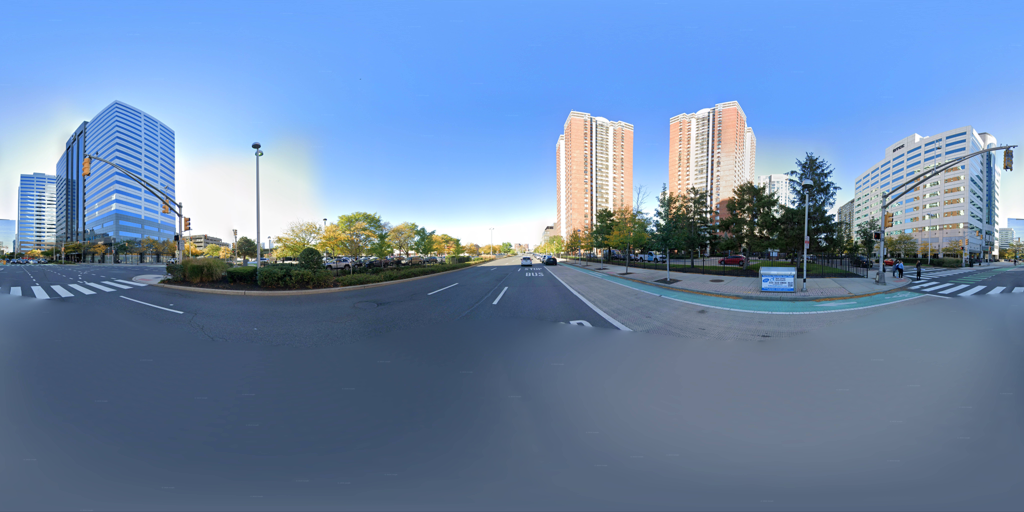

In [10]:
from streetview import get_panorama

with get_conn() as (conn, c):
    # Select pano ID
    pano_id = "r2474rGJROl9Om0w3I_oNg"
    print(pano_id)
    pano = get_panorama(pano_id=pano_id, multi_threaded=True, http_proxy=PROXY_IP)
    print(pano.size)
    # Downscale for notebook
    pano_ds = pano.copy()
    pano_ds.thumbnail((1024, 1024))
    pano_ds.show()

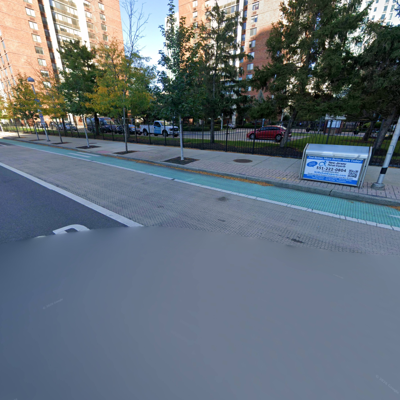

In [21]:
import numpy as np
import math
import cv2
from PIL import Image
from dataclasses import dataclass, field
from typing import Iterable, Iterator, Optional
import itertools

def pillow_to_cv2(img):
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

def cv2_to_pillow(img):
    return Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

# --- Stage 1: Configuration & Reprojection ---

@dataclass
class Config:
    fov_deg: float = 90.0
    yaw_step_deg: float = 60.0
    pitch_deg: tuple[float, ...] = (-20.0, 10.0, 35.0)
    view_size: int = 2560
    tile: int = 640
    tile_overlap: float = 0.25
    model_dir: str = "./wechat_models"
    upscale_factors: tuple[float, ...] = (1.0, 2.0, 4.0)
    rotations_deg: tuple[int, ...] = (0, 90, 180, 270)
    min_crop_px: int = 12
    box_merge_iou: float = 0.2
    decode_pad_px: int = 8
    decode_pad_frac: float = 0.15
    cluster_radius_m: float = 25.0
    triangulate: bool = True

@dataclass
class ViewParams:
    yaw_deg: float
    pitch_deg: float
    fov_deg: float
    size: int

def generate_views(cfg: Config) -> list[ViewParams]:
    yaws = np.arange(0.0, 360.0, cfg.yaw_step_deg)
    return [
        ViewParams(float(y), float(p), cfg.fov_deg, cfg.view_size)
        for y in yaws for p in cfg.pitch_deg
    ]

def equirect_to_perspective(equ: np.ndarray, view: ViewParams):
    H, W = equ.shape[:2]
    out = view.size
    wFOV = view.fov_deg
    hFOV = wFOV
    w_len = math.tan(math.radians(wFOV / 2.0))
    h_len = math.tan(math.radians(hFOV / 2.0))
 
    x_map = np.ones((out, out), np.float32)
    y_map = np.tile(np.linspace(-w_len, w_len, out), (out, 1)).astype(np.float32)
    z_map = -np.tile(np.linspace(-h_len, h_len, out), (out, 1)).T.astype(np.float32)
 
    norm = np.sqrt(x_map ** 2 + y_map ** 2 + z_map ** 2)
    xyz = np.stack((x_map, y_map, z_map), axis=2) / norm[:, :, None]
 
    y_axis = np.array([0.0, 1.0, 0.0], np.float32)
    z_axis = np.array([0.0, 0.0, 1.0], np.float32)
    R_yaw, _ = cv2.Rodrigues(z_axis * math.radians(view.yaw_deg))
    R_pitch, _ = cv2.Rodrigues(np.dot(R_yaw, y_axis) * math.radians(-view.pitch_deg))
 
    xyz = xyz.reshape((-1, 3)).T
    xyz = np.dot(R_pitch, np.dot(R_yaw, xyz)).T
 
    lat = np.arcsin(np.clip(xyz[:, 2], -1.0, 1.0))
    lon = np.arctan2(xyz[:, 1], xyz[:, 0])
    lon_deg = np.degrees(lon).reshape((out, out))
    lat_deg = -np.degrees(lat).reshape((out, out))  # +down, matches image y
 
    map_x = (lon_deg / 180.0 * (W / 2.0) + W / 2.0).astype(np.float32)
    map_y = (lat_deg / 90.0 * (H / 2.0) + H / 2.0).astype(np.float32)
    img = cv2.remap(equ, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_WRAP)
 
    azimuth_map = lon_deg                 # already pano-relative
    elevation_map = -lat_deg              # +up
    return img, azimuth_map, elevation_map

# Verify reprojection using extracted view
cfg = Config()
equ = pillow_to_cv2(pano)
view = generate_views(cfg)[3] # sample view
img, _, _ = equirect_to_perspective(equ, view)
img_pil = cv2_to_pillow(img)
img_pil_thumb = img_pil.copy()
img_pil_thumb.thumbnail((400, 400))
display(img_pil_thumb)

In [22]:
import os
import urllib.request
import zxingcpp
from pyzbar.pyzbar import decode as _pyzbar_decode

# --- Fetch WeChat Models (if needed) ---
os.makedirs(cfg.model_dir, exist_ok=True)
base_url = "https://raw.githubusercontent.com/WeChatCV/opencv_3rdparty/wechat_qrcode/"
files = ["detect.prototxt", "detect.caffemodel", "sr.prototxt", "sr.caffemodel"]
for f in files:
    path = os.path.join(cfg.model_dir, f)
    if not os.path.exists(path):
        print(f"Downloading {f}...")
        urllib.request.urlretrieve(base_url + f, path)

# --- Stage 2 & 3 & 4: Tiling & QR Search ---

def tile_positions(size: int, tile: int, overlap: float) -> list[int]:
    step = max(1, int(round(tile * (1.0 - overlap))))
    xs = list(range(0, max(1, size - tile + 1), step))
    if xs[-1] != size - tile:
        xs.append(size - tile)
    return xs

def iter_tiles(img: np.ndarray, cfg: Config) -> Iterator[tuple[int, int, np.ndarray]]:
    h, w = img.shape[:2]
    tile = min(cfg.tile, h, w)
    for y0 in tile_positions(h, tile, cfg.tile_overlap):
        for x0 in tile_positions(w, tile, cfg.tile_overlap):
            yield x0, y0, img[y0:y0 + tile, x0:x0 + tile]

def _aabb(box: np.ndarray) -> tuple[float, float, float, float]:
    x0, y0 = box.min(0)
    x1, y1 = box.max(0)
    return float(x0), float(y0), float(x1), float(y1)

def _center(box: np.ndarray) -> tuple[float, float]:
    c = box.mean(0)
    return float(c[0]), float(c[1])

def _iou(a, b) -> float:
    ix0, iy0 = max(a[0], b[0]), max(a[1], b[1])
    ix1, iy1 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix1 - ix0), max(0.0, iy1 - iy0)
    inter = iw * ih
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def merge_boxes(aabbs: list[tuple], iou_thresh: float) -> list[tuple]:
    merged = list(aabbs)
    changed = True
    while changed:
        changed = False
        out = []
        for box in merged:
            for i, m in enumerate(out):
                if _iou(box, m) > iou_thresh:
                    out[i] = (min(box[0], m[0]), min(box[1], m[1]),
                              max(box[2], m[2]), max(box[3], m[3]))
                    changed = True
                    break
            else:
                out.append(box)
        merged = out
    return merged

class QRScanner:
    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.wechat = self._load_wechat(cfg.model_dir)

    @staticmethod
    def _load_wechat(model_dir: str):
        f = lambda n: os.path.join(model_dir, n)
        files = ["detect.prototxt", "detect.caffemodel", "sr.prototxt", "sr.caffemodel"]
        if not all(os.path.exists(f(n)) for n in files):
            return None
        return cv2.wechat_qrcode.WeChatQRCode(
            f("detect.prototxt"), f("detect.caffemodel"),
            f("sr.prototxt"), f("sr.caffemodel"),
        )

    def _wechat_detect(self, img: np.ndarray):
        if self.wechat is None: return []
        try:
            texts, pts = self.wechat.detectAndDecode(img)
        except Exception:
            return []
        out = []
        for txt, box in itertools.zip_longest(list(texts), list(pts), fillvalue=None):
            b = np.asarray(box, np.float32).reshape(-1, 2) if box is not None else None
            out.append((txt if txt else None, b))
        return out

    @staticmethod
    def _zxing(img: np.ndarray):
        out = []
        try:
            for r in zxingcpp.read_barcodes(img):
                if not r.text: continue
                try:
                    p = r.position
                    box = np.array([[p.top_left.x, p.top_left.y],
                                    [p.top_right.x, p.top_right.y],
                                    [p.bottom_right.x, p.bottom_right.y],
                                    [p.bottom_left.x, p.bottom_left.y]], np.float32)
                except Exception:
                    box = None
                out.append((r.text, box))
        except Exception: pass
        return out

    @staticmethod
    def _pyzbar(img: np.ndarray):
        out = []
        try:
            for s in _pyzbar_decode(img):
                if s.type != "QRCODE" or not s.data: continue
                text = s.data.decode("utf-8", "replace")
                if getattr(s, "polygon", None):
                    box = np.array([[pt.x, pt.y] for pt in s.polygon], np.float32)
                else:
                    r = s.rect
                    box = np.array([[r.left, r.top], [r.left + r.width, r.top],
                                    [r.left + r.width, r.top + r.height],
                                    [r.left, r.top + r.height]], np.float32)
                out.append((text, box))
        except Exception: pass
        return out

    def _software_decode(self, img: np.ndarray):
        return self._zxing(img) + self._pyzbar(img)

    def _variants(self, crop: np.ndarray) -> Iterator[np.ndarray]:
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY) if crop.ndim == 3 else crop
        for scale in self.cfg.upscale_factors:
            g = (cv2.resize(gray, None, fx=scale, fy=scale,
                            interpolation=cv2.INTER_CUBIC) if scale != 1.0 else gray)
            variants = [g]
            try:
                variants.append(cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1])
                m = min(g.shape[:2])
                bs = max(3, min(31, m if m % 2 == 1 else m - 1))
                variants.append(cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, bs, 5))
            except Exception: pass
            for base in variants:
                for rot in self.cfg.rotations_deg:
                    if rot == 0: yield base
                    else:
                        k = {90: cv2.ROTATE_90_CLOCKWISE, 180: cv2.ROTATE_180, 270: cv2.ROTATE_90_COUNTERCLOCKWISE}[rot]
                        yield cv2.rotate(base, k)

    def _ensemble_decode(self, crop: np.ndarray) -> set[str]:
        results = set()
        for v in self._variants(crop):
            for text, _ in self._software_decode(v):
                results.add(text)
            if results: break
        return results

    def scan_view(self, view_img: np.ndarray) -> list[tuple[str, tuple[float, float]]]:
        H, W = view_img.shape[:2]
        results = {}
        undecoded = []

        def collect(img, ox, oy):
            for text, box in self._wechat_detect(img):
                b = None
                if box is not None:
                    b = box.copy()
                    b[:, 0] += ox
                    b[:, 1] += oy
                if text:
                    c = _center(b) if b is not None else (ox + img.shape[1] / 2, oy + img.shape[0] / 2)
                    results.setdefault(text, c)
                elif b is not None:
                    undecoded.append(_aabb(b))
            for text, box in self._software_decode(img):
                if box is not None:
                    b = box.copy()
                    b[:, 0] += ox
                    b[:, 1] += oy
                    c = _center(b)
                else:
                    c = (ox + img.shape[1] / 2, oy + img.shape[0] / 2)
                results.setdefault(text, c)

        # Scale 0: whole view
        collect(view_img, 0, 0)

        # Scale 1: tiles
        if self.cfg.tile:
            for x0, y0, tile in iter_tiles(view_img, self.cfg):
                collect(tile, x0, y0)

        # Decode globally
        for (x0, y0, x1, y1) in merge_boxes(undecoded, self.cfg.box_merge_iou):
            pad = max(self.cfg.decode_pad_px, self.cfg.decode_pad_frac * max(x1 - x0, y1 - y0))
            cx0, cy0 = int(max(0, x0 - pad)), int(max(0, y0 - pad))
            cx1, cy1 = int(min(W, x1 + pad)), int(min(H, y1 + pad))
            if cx1 - cx0 < self.cfg.min_crop_px or cy1 - cy0 < self.cfg.min_crop_px:
                continue
            crop = view_img[cy0:cy1, cx0:cx1]
            for payload in self._ensemble_decode(crop):
                results.setdefault(payload, ((cx0 + cx1) / 2.0, (cy0 + cy1) / 2.0))

        return list(results.items())

Initializing Scanner... (using models from ./wechat_models)
Scanning panorama across 18 views...


Scanning views:   0%|          | 0/18 [00:00<?, ?it/s]

Found 1 QR code(s) in view (yaw=60.0°, pitch=-20.0°)
Payload: https://vqr.vc/9ddCHALxW


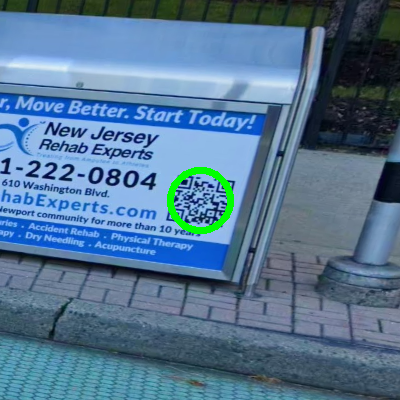

Found 1 QR code(s) in view (yaw=60.0°, pitch=10.0°)
Repeat Payload: https://vqr.vc/9ddCHALxW
Found 1 QR code(s) in view (yaw=120.0°, pitch=-20.0°)
Repeat Payload: https://vqr.vc/9ddCHALxW
Found 1 QR code(s) in view (yaw=120.0°, pitch=10.0°)
Repeat Payload: https://vqr.vc/9ddCHALxW
Extraction complete! Found 1 unique code(s) over 4 detection(s).


In [24]:
@dataclass
class PanoMeta:
    pano_id: str
    lat: float
    lng: float
    heading_deg: float = 0.0

@dataclass
class Detection:
    payload: str
    pano_id: str
    pano_lat: float
    pano_lng: float
    azimuth_deg: float
    elevation_deg: float
    compass_bearing_deg: float
    view: ViewParams
    
@dataclass
class MappedCode:
    payload: str
    lat: Optional[float]
    lng: Optional[float]
    observations: list[Detection] = field(default_factory=list)

def detections_from_view(
    hits: list[tuple[str, tuple[float, float]]],
    az_map: np.ndarray, el_map: np.ndarray,
    view: ViewParams, pano: PanoMeta,
) -> list[Detection]:
    out = []
    H, W = az_map.shape
    for payload, (cx, cy) in hits:
        px = int(np.clip(round(cx), 0, W - 1))
        py = int(np.clip(round(cy), 0, H - 1))
        az = float(az_map[py, px])
        el = float(el_map[py, px])
        bearing = (pano.heading_deg + az) % 360.0
        out.append(Detection(
            payload=payload, pano_id=pano.pano_id,
            pano_lat=pano.lat, pano_lng=pano.lng,
            azimuth_deg=az, elevation_deg=el,
            compass_bearing_deg=bearing, view=view,
        ))
    return out

# --- Stage 5: Demo execution on the test panorama ---
from IPython.display import display
from tqdm.auto import tqdm

print(f"Initializing Scanner... (using models from {cfg.model_dir})")
scanner = QRScanner(cfg)
meta = PanoMeta(pano_id=pano_id, lat=0.0, lng=0.0, heading_deg=0.0) # placeholders for demo

all_detections = []
views = generate_views(cfg)
seen_payloads = set()

print(f"Scanning panorama across {len(views)} views...")
for view in tqdm(views, desc="Scanning views"):
    img, az_map, el_map = equirect_to_perspective(equ, view)
    hits = scanner.scan_view(img)
    if hits:
        print(f"Found {len(hits)} QR code(s) in view (yaw={view.yaw_deg}°, pitch={view.pitch_deg}°)")
        for payload, (cx, cy) in hits:
            if payload not in seen_payloads:
                print(f"Payload: {payload}")
                seen_payloads.add(payload)
                
                # Draw a bounding circle around the detection
                disp_img = img.copy()
                cv2.circle(disp_img, (int(cx), int(cy)), 30, (0, 255, 0), 5)
                
                disp_pil = cv2_to_pillow(disp_img)
                # Crop around the code to show it clearly in the notebook
                pad = 200
                left = max(0, int(cx) - pad)
                top = max(0, int(cy) - pad)
                right = min(img.shape[1], int(cx) + pad)
                bottom = min(img.shape[0], int(cy) + pad)
                
                crop_pil = disp_pil.crop((left, top, right, bottom))
                display(crop_pil)
            else:
                print(f"Repeat Payload: {payload}")
                
        all_detections.extend(detections_from_view(hits, az_map, el_map, view, meta))
            
if not all_detections:
    print("No QR codes were found in this panorama.")
else:
    print(f"Extraction complete! Found {len(set(d.payload for d in all_detections))} unique code(s) over {len(all_detections)} detection(s).")